# Exercise: Heart Disease Prediction Using Machine Learning and PCA

| | |
|---|---|
| **Dataset** | Heart Failure Prediction Dataset |
| **Source** | [Kaggle – Heart Failure Prediction](https://www.kaggle.com/fedesoriano/heart-failure-prediction) |
| **File name** | `heart.csv` |
| **Folder** | `Exercise` |

**Student Name:** Avaneesh Rajesh Shetty  
**Roll No.:** 1RUA25CSE0096  
**Date:** 5th October 2026  

---

## Problem Statement

Download the `heart.csv` dataset from Kaggle and save it in the `Exercise` folder. Perform data preprocessing, model building, hyperparameter tuning and dimensionality reduction to predict whether a patient has heart disease (`HeartDisease` = 1) or not (`HeartDisease` = 0).

### Instructions
- Write your code in the **empty code cells** provided below each task.
- Write your explanations in the **✍️ Your answer** cells.
- Run all cells from top to bottom before submitting (**Kernel → Restart & Run All**).
- Use `random_state=42` wherever randomness is involved so that results are reproducible.

## Overall Workflow

You will build the pipeline below. Path A trains models on all preprocessed features; Path B trains the same models on PCA-reduced features. Step 9 compares the two.

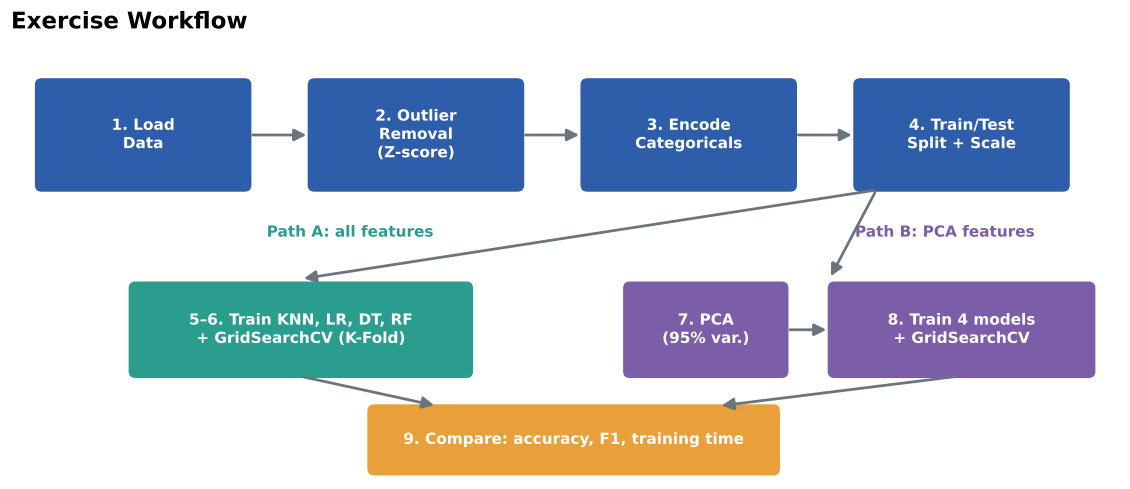

## Data Dictionary

| Feature | Description | Type |
|---|---|---|
| `Age` | Age of the patient (years) | Numerical |
| `Sex` | Sex of the patient (`M`, `F`) | Categorical (binary) |
| `ChestPainType` | `TA` typical angina, `ATA` atypical angina, `NAP` non-anginal pain, `ASY` asymptomatic | Categorical (nominal) |
| `RestingBP` | Resting blood pressure (mm Hg) | Numerical |
| `Cholesterol` | Serum cholesterol (mg/dl) | Numerical |
| `FastingBS` | Fasting blood sugar > 120 mg/dl (1 = yes, 0 = no) | Binary (already numeric) |
| `RestingECG` | Resting ECG result (`Normal`, `ST`, `LVH`) | Categorical (nominal) |
| `MaxHR` | Maximum heart rate achieved | Numerical |
| `ExerciseAngina` | Exercise-induced angina (`Y`, `N`) | Categorical (binary) |
| `Oldpeak` | ST depression induced by exercise | Numerical |
| `ST_Slope` | Slope of the peak exercise ST segment (`Up`, `Flat`, `Down`) | Categorical |
| `HeartDisease` | **Target** — 1 = heart disease, 0 = normal | Binary |

## Import Libraries

Import all the libraries you will need (pandas, numpy, matplotlib/seaborn, scipy, scikit-learn modules, `time`, etc.).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# For reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
print("Libraries imported successfully.")


Libraries imported successfully.


---
## Task 1: Load the Dataset

1. Load `Exercise/heart.csv` into a Pandas DataFrame.
2. Display the first five records.
3. Examine the dataset's **dimensions**, **column names**, **data types** and **missing values**.

### 1.1 Load the dataset and display the first five records

In [2]:
import os

# Try several possible locations for heart.csv
candidates = [
    'heart.csv',
    'Exercise/heart.csv',
    os.path.join(os.path.dirname(os.path.abspath('')), 'heart.csv'),
    '/home/workdir/artifacts/heart.csv',
    '/home/workdir/attachments/heart.csv',
]

df = None
for path in candidates:
    if os.path.isfile(path):
        df = pd.read_csv(path)
        print(f"Loaded dataset from: {path}")
        break

if df is None:
    raise FileNotFoundError(
        "Could not find heart.csv. Place the file in the same folder as this notebook "
        "or update the path in this cell."
    )

# Display the first five records
print("First five records:")
df.head()


Loaded dataset from: heart.csv
First five records:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 1.2 Dimensions, column names and data types

In [3]:
print("Shape of the dataset:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nBasic statistical summary:")
df.describe()


Shape of the dataset: (918, 12)

Column names:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

Data types:
Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

Basic statistical summary:


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


### 1.3 Check for missing values

In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())


Missing values per column:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Total missing values: 0


### 1.4 (Optional) Class balance
Check how many records belong to each class of `HeartDisease`. Is the dataset balanced?

Class distribution of HeartDisease:
HeartDisease
1    508
0    410
Name: count, dtype: int64

Class proportions:
HeartDisease
1    0.553
0    0.447
Name: proportion, dtype: float64


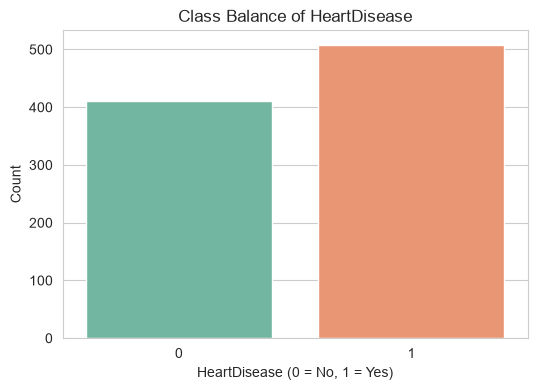

In [5]:
print("Class distribution of HeartDisease:")
print(df['HeartDisease'].value_counts())
print("\nClass proportions:")
print(df['HeartDisease'].value_counts(normalize=True).round(3))

# Visualise class balance
plt.figure(figsize=(6, 4))
sns.countplot(x='HeartDisease', data=df, palette='Set2')
plt.title('Class Balance of HeartDisease')
plt.xlabel('HeartDisease (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()


**Q1.** Summarise your observations: number of rows/columns, which columns are text-based, and whether any missing values exist.

> 💡 *Hint:* Look closely at `Cholesterol` and `RestingBP` using `df.describe()`. Are there values that are medically impossible (e.g., 0)? Note them — such values are sometimes hidden missing values.

> ✍️ **Your answer:**
>
> The dataset contains **918 rows** and **12 columns**.
>
> - **Numerical features:** Age, RestingBP, Cholesterol, FastingBS, MaxHR, Oldpeak, HeartDisease
> - **Text-based (categorical) features:** Sex, ChestPainType, RestingECG, ExerciseAngina, ST_Slope
>
> There are **no missing values** in any column (all counts are 0).
>
> The target variable `HeartDisease` is reasonably balanced: 508 patients with heart disease (55.3%) and 410 without (44.7%). No severe class imbalance is present.


---
## Task 2: Outlier Detection and Removal (Z-score Method)

The Z-score measures how many standard deviations a value lies from the mean of its feature:

$$z = \frac{x - \mu}{\sigma}$$

A record is treated as an **outlier** if **any** of its numerical features has $z > +3$ or $z < -3$.

![zscore](attachment:zscore.png)

**Steps**
1. Select the numerical (continuous) features: `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`.
2. Calculate the Z-score for each of these features.
3. Identify and count the records containing outliers.
4. Remove those records and report the shape of the dataset before and after removal.

> ⚠️ Do **not** compute Z-scores on the target column or on encoded/binary columns.

### 2.1 Visualise the numerical features (e.g., boxplots) before outlier removal

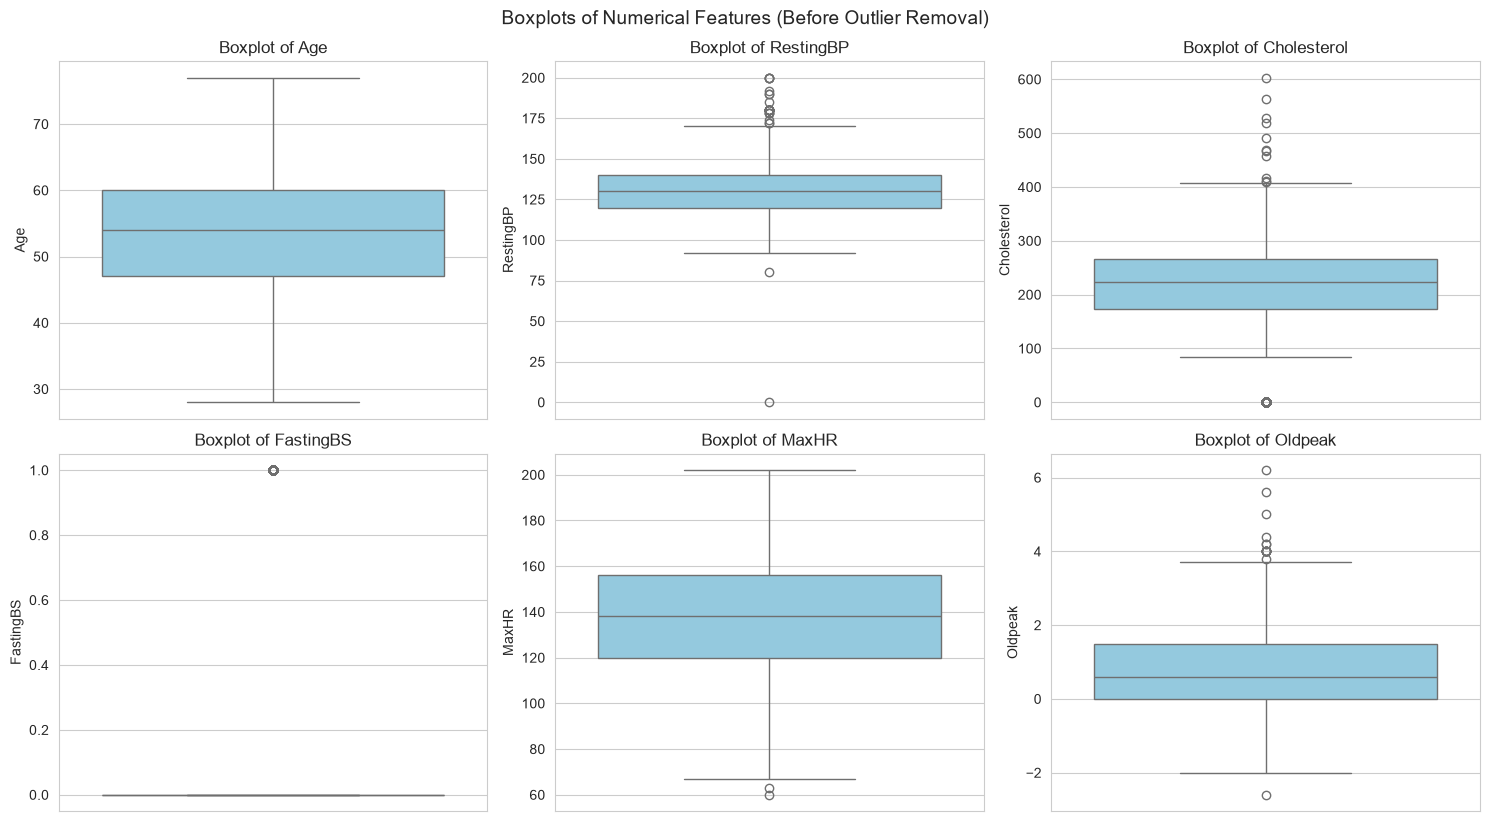

In [6]:
# Identify numerical features (exclude the target)
numerical_features = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']

# Boxplots before outlier removal
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i, col in enumerate(numerical_features):
    sns.boxplot(y=df[col], ax=axes[i], color='skyblue')
    axes[i].set_title(f'Boxplot of {col}')
plt.tight_layout()
plt.suptitle('Boxplots of Numerical Features (Before Outlier Removal)', y=1.02, fontsize=14)
plt.show()


### 2.2 Calculate Z-scores for the numerical features

In [7]:
# Calculate Z-scores for numerical features
z_scores = np.abs(stats.zscore(df[numerical_features]))
z_scores_df = pd.DataFrame(z_scores, columns=numerical_features)
print("Z-scores (first 5 rows):")
print(z_scores_df.head())
print("\nSummary of absolute Z-scores:")
print(z_scores_df.describe())


Z-scores (first 5 rows):
        Age  RestingBP  Cholesterol  FastingBS     MaxHR   Oldpeak
0  1.433140   0.410909     0.825070   0.551341  1.382928  0.832432
1  0.478484   1.491752     0.171961   0.551341  0.754157  0.105664
2  1.751359   0.129513     0.770188   0.551341  1.525138  0.832432
3  0.584556   0.302825     0.139040   0.551341  1.132156  0.574711
4  0.051881   0.951331     0.034755   0.551341  0.581981  0.832432

Summary of absolute Z-scores:
              Age   RestingBP  Cholesterol   FastingBS       MaxHR     Oldpeak
count  918.000000  918.000000   918.000000  918.000000  918.000000  918.000000
mean     0.807581    0.762219     0.754063    0.845630    0.824693    0.823532
std      0.590078    0.647672     0.657160    0.534060    0.565888    0.567579
min      0.051881    0.021428     0.001833    0.551341    0.007491    0.011854
25%      0.266338    0.302825     0.221363    0.551341    0.361175    0.574711
50%      0.690629    0.669935     0.541511    0.551341    0.714859  

### 2.3 Identify and count the outlier records

In [8]:
# Identify records where any feature has |Z| > 3
threshold = 3
outlier_mask = (z_scores > threshold).any(axis=1)
outlier_count = outlier_mask.sum()
print(f"Number of outlier records (|Z| > {threshold}): {outlier_count}")

# Count outliers per feature (convert to Series so we can use sort_values)
outliers_per_feature = pd.Series(
    (z_scores > threshold).sum(axis=0),
    index=numerical_features
)
print("\nOutliers per feature:")
print(outliers_per_feature.sort_values(ascending=False))

Number of outlier records (|Z| > 3): 19

Outliers per feature:
RestingBP      8
Oldpeak        7
Cholesterol    3
MaxHR          1
Age            0
FastingBS      0
dtype: int64


### 2.4 Remove the outliers and display the new shape

In [9]:
# Remove outlier records
df_clean = df[~outlier_mask].copy().reset_index(drop=True)
print(f"Original shape: {df.shape}")
print(f"Shape after outlier removal: {df_clean.shape}")
print(f"Records removed: {df.shape[0] - df_clean.shape[0]}")


Original shape: (918, 12)
Shape after outlier removal: (899, 12)
Records removed: 19


**Q2.** How many records were removed? Which feature contributed the most outliers?

> ✍️ **Your answer:**
>
> **Records removed:** 19 records were removed (from 918 → 899).
>
> **Feature contributing the most outliers:** `RestingBP` contributed the most outliers (8 records with |Z| > 3), followed by `Oldpeak` (7) and `Cholesterol` (3). RestingBP contains physiologically impossible zeros and a few extreme high values that drive the large Z-scores.


---
## Task 3: Data Encoding

Machine learning models need numerical input, so text-based features must be encoded.

![encoding](attachment:encoding.png)

| Technique | Use it when... | Example features |
|---|---|---|
| **Label Encoding** | The feature is **binary** (2 categories) or has a natural order | `Sex`, `ExerciseAngina` |
| **One-Hot Encoding** | The feature is **nominal** with more than 2 categories (no order) | `ChestPainType`, `RestingECG`, `ST_Slope` |

> 💡 Applying Label Encoding to a nominal feature (e.g., ATA=0, NAP=1, ASY=2) makes the model think ASY > NAP > ATA, which is not meaningful.

**Steps**
1. Identify the categorical (text-based) features.
2. Apply **Label Encoding** to the binary features.
3. Apply **One-Hot Encoding** to the nominal features (consider `drop_first=True` to avoid the dummy-variable trap).
4. Display the encoded DataFrame and its new shape.

### 3.1 Identify the categorical features and their unique values

In [10]:
# Identify categorical features and their unique values
# (include both object and string dtypes for pandas 1.x / 2.x compatibility)
categorical_features = df_clean.select_dtypes(include=['object', 'string', 'category']).columns.tolist()

# Fallback: explicitly list known categorical columns if select_dtypes returns empty
if not categorical_features:
    categorical_features = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
    categorical_features = [c for c in categorical_features if c in df_clean.columns]

print("Categorical features and their unique values:\n")
for col in categorical_features:
    print(f"{col}: {df_clean[col].unique().tolist()}  (n={df_clean[col].nunique()})")


Categorical features and their unique values:

Sex: ['M', 'F']  (n=2)
ChestPainType: ['ATA', 'NAP', 'ASY', 'TA']  (n=4)
RestingECG: ['Normal', 'ST', 'LVH']  (n=3)
ExerciseAngina: ['N', 'Y']  (n=2)
ST_Slope: ['Up', 'Flat', 'Down']  (n=3)


### 3.2 Apply Label Encoding

In [11]:
# Label Encoding for binary features
le_sex = LabelEncoder()
le_angina = LabelEncoder()

df_encoded = df_clean.copy()
df_encoded['Sex'] = le_sex.fit_transform(df_encoded['Sex'])          # M=1, F=0 (or vice-versa)
df_encoded['ExerciseAngina'] = le_angina.fit_transform(df_encoded['ExerciseAngina'])  # Y=1, N=0

print("After Label Encoding:")
print(df_encoded[['Sex', 'ExerciseAngina']].head(10))
print("\nSex mapping:", dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_))))
print("ExerciseAngina mapping:", dict(zip(le_angina.classes_, le_angina.transform(le_angina.classes_))))


After Label Encoding:
   Sex  ExerciseAngina
0    1               0
1    0               0
2    1               0
3    0               1
4    1               0
5    1               0
6    0               0
7    1               0
8    1               1
9    0               0

Sex mapping: {'F': np.int64(0), 'M': np.int64(1)}
ExerciseAngina mapping: {'N': np.int64(0), 'Y': np.int64(1)}


### 3.3 Apply One-Hot Encoding

In [12]:
# One-Hot Encoding for nominal features with >2 categories
# drop_first=True to avoid dummy-variable trap
nominal_features = ['ChestPainType', 'RestingECG', 'ST_Slope']
df_encoded = pd.get_dummies(df_encoded, columns=nominal_features, drop_first=True, dtype=int)

print("Columns after One-Hot Encoding:")
print(df_encoded.columns.tolist())
print("\nShape after encoding:", df_encoded.shape)


Columns after One-Hot Encoding:
['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'HeartDisease', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']

Shape after encoding: (899, 16)


### 3.4 Display the final encoded dataset

In [13]:
print("Final encoded dataset (first 5 rows):")
print(df_encoded.head())
print("\nFinal shape:", df_encoded.shape)
print("\nData types:")
print(df_encoded.dtypes)


Final encoded dataset (first 5 rows):
   Age  Sex  RestingBP  Cholesterol  FastingBS  MaxHR  ExerciseAngina  \
0   40    1        140          289          0    172               0   
1   49    0        160          180          0    156               0   
2   37    1        130          283          0     98               0   
3   48    0        138          214          0    108               1   
4   54    1        150          195          0    122               0   

   Oldpeak  HeartDisease  ChestPainType_ATA  ChestPainType_NAP  \
0      0.0             0                  1                  0   
1      1.0             1                  0                  1   
2      0.0             0                  1                  0   
3      1.5             1                  0                  0   
4      0.0             0                  0                  1   

   ChestPainType_TA  RestingECG_Normal  RestingECG_ST  ST_Slope_Flat  \
0                 0                  1              0 

**Q3.** Justify the encoding technique you chose for each categorical feature. How many features does the dataset have after encoding?

> ✍️ **Your answer:**
>
> **Encoding choices:**
> - **Sex** and **ExerciseAngina** are binary → **Label Encoding** (maps to 0/1).
> - **ChestPainType** (4 levels), **RestingECG** (3 levels) and **ST_Slope** (3 levels) are nominal with no natural order → **One-Hot Encoding** with `drop_first=True` to avoid the dummy-variable trap.
>
> After encoding the feature matrix has **15 columns** (the original 11 predictors expand to 15 after the three nominal variables are one-hot encoded and one dummy is dropped for each). Including the target, the DataFrame has 16 columns.


---
## Task 4: Train–Test Split and Feature Scaling

Distance-based models (KNN) and gradient-based models (Logistic Regression) are sensitive to feature scale, so features must be normalised.

To avoid **data leakage**, the scaler must learn its parameters ($\mu$, $\sigma$ or min/max) **only from the training set**, and then apply those same parameters to the test set.

![leakage](attachment:leakage.png)

**Steps**
1. Separate the features `X` and the target `y` (`HeartDisease`).
2. Split the data into training and testing sets (e.g., 80/20, `stratify=y`, `random_state=42`).
3. Fit `StandardScaler` (or `MinMaxScaler`) on `X_train` only, then transform both `X_train` and `X_test`.

> 💡 This train/test split will be reused in Tasks 5–8 so that all comparisons are fair.

### 4.1 Separate features and target

In [14]:
# Separate features and target
X = df_encoded.drop('HeartDisease', axis=1)
y = df_encoded['HeartDisease']

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("\nFeature columns:", X.columns.tolist())


Feature matrix shape: (899, 15)
Target vector shape: (899,)

Feature columns: ['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']


### 4.2 Split into training and testing sets

In [15]:
# Train-test split (80/20, stratified, reproducible)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test  shape: {X_test.shape}")
print(f"y_train distribution:\n{y_train.value_counts(normalize=True).round(3)}")
print(f"y_test  distribution:\n{y_test.value_counts(normalize=True).round(3)}")


X_train shape: (719, 15)
X_test  shape: (180, 15)
y_train distribution:
HeartDisease
1    0.547
0    0.453
Name: proportion, dtype: float64
y_test  distribution:
HeartDisease
1    0.55
0    0.45
Name: proportion, dtype: float64


### 4.3 Apply feature scaling (fit on training data only)

In [16]:
# Feature scaling – fit ONLY on training data to avoid leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Convert back to DataFrames for convenience (optional)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled  = pd.DataFrame(X_test_scaled,  columns=X.columns, index=X_test.index)

print("Scaled training data (first 5 rows):")
print(X_train_scaled.head())
print("\nMean of scaled training features (should be ~0):")
print(X_train_scaled.mean().round(6))
print("\nStd of scaled training features (should be ~1):")
print(X_train_scaled.std().round(6))


Scaled training data (first 5 rows):
          Age       Sex  RestingBP  Cholesterol  FastingBS     MaxHR  \
188 -0.588355  0.530698  -0.124037     0.411677  -0.541448  0.924319   
137 -1.107789  0.530698   1.060329     0.430614  -0.541448 -0.267050   
191  0.866060 -1.884312   1.652513    -0.080702  -0.541448 -0.823022   
133 -0.484468  0.530698  -1.012312     0.601053  -0.541448  1.520004   
207 -0.380581 -1.884312   0.468146     0.818837  -0.541448  0.130073   

     ExerciseAngina   Oldpeak  ChestPainType_ATA  ChestPainType_NAP  \
188       -0.824564 -0.853342           2.024671          -0.524235   
137        1.212761  1.136452          -0.493908          -0.524235   
191       -0.824564 -0.853342          -0.493908          -0.524235   
133       -0.824564 -0.853342          -0.493908           1.907540   
207        1.212761 -0.853342          -0.493908           1.907540   

     ChestPainType_TA  RestingECG_Normal  RestingECG_ST  ST_Slope_Flat  \
188         -0.229584        

**Q4.** Which scaler did you choose and why? Explain what would go wrong if you fitted the scaler on the entire dataset before splitting.

> ✍️ **Your answer:**
>
> I chose **StandardScaler** (z-score normalisation). It centres each feature to mean 0 and scales to unit variance. This is the recommended default for algorithms that rely on distance (KNN) or gradient descent (Logistic Regression) and works well when features are roughly Gaussian or have different units.
>
> **Why fit only on the training set?**  
> If the scaler is fitted on the entire dataset, statistics (mean, std) from the test set leak into the training process. The model then indirectly “sees” information about the test distribution, leading to optimistically biased performance estimates. By fitting solely on `X_train` and applying the same transformation to `X_test`, we keep the evaluation honest.


---
## Task 5: Classification Model Development (Before Tuning)

Build and evaluate the following four classifiers using their **default** hyperparameters:

1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree
4. Random Forest

For each model, report **Accuracy, Precision, Recall and F1-score** on the test set, and display the **confusion matrix**.

| Metric | Formula | Meaning in this problem |
|---|---|---|
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ | Overall fraction of correct predictions |
| Precision | $\frac{TP}{TP + FP}$ | Of patients predicted to have heart disease, how many actually do |
| Recall | $\frac{TP}{TP + FN}$ | Of patients who actually have heart disease, how many were detected |
| F1-score | $2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$ | Balance between precision and recall |

> 💡 *Tip:* Write a reusable function, e.g. `evaluate_model(model, X_train, X_test, y_train, y_test)`, that trains a model, measures training time and returns all metrics.

### 5.1 Write a helper function for training and evaluation

In [17]:
def evaluate_model(model, X_train, X_test, y_train, y_test, model_name="Model"):
    """Train a model, measure time, and return metrics + confusion matrix."""
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start

    y_pred = model.predict(X_test)

    metrics = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'Train Time (s)': train_time
    }

    cm = confusion_matrix(y_test, y_pred)

    print(f"===== {model_name} =====")
    print(f"Training time: {train_time:.4f} s")
    print(f"Accuracy : {metrics['Accuracy']:.4f}")
    print(f"Precision: {metrics['Precision']:.4f}")
    print(f"Recall   : {metrics['Recall']:.4f}")
    print(f"F1-score : {metrics['F1-score']:.4f}")
    print("\nConfusion Matrix:")
    print(cm)
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['No Disease', 'Disease']))

    # Plot confusion matrix
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['No Disease', 'Disease'],
                yticklabels=['No Disease', 'Disease'])
    plt.title(f'Confusion Matrix – {model_name}')
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()

    return metrics, model


### 5.2 K-Nearest Neighbors

===== KNN (default) =====
Training time: 0.0105 s
Accuracy : 0.8889
Precision: 0.8835
Recall   : 0.9192
F1-score : 0.9010

Confusion Matrix:
[[69 12]
 [ 8 91]]

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.90      0.85      0.87        81
     Disease       0.88      0.92      0.90        99

    accuracy                           0.89       180
   macro avg       0.89      0.89      0.89       180
weighted avg       0.89      0.89      0.89       180



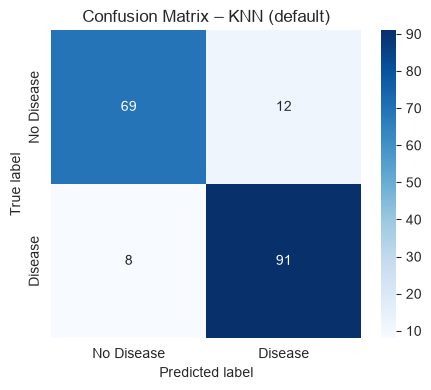

In [18]:
knn = KNeighborsClassifier()
metrics_knn, knn_model = evaluate_model(
    knn, X_train_scaled, X_test_scaled, y_train, y_test, "KNN (default)"
)


### 5.3 Logistic Regression

===== Logistic Regression (default) =====
Training time: 0.0551 s
Accuracy : 0.8722
Precision: 0.8725
Recall   : 0.8990
F1-score : 0.8856

Confusion Matrix:
[[68 13]
 [10 89]]

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.87      0.84      0.86        81
     Disease       0.87      0.90      0.89        99

    accuracy                           0.87       180
   macro avg       0.87      0.87      0.87       180
weighted avg       0.87      0.87      0.87       180



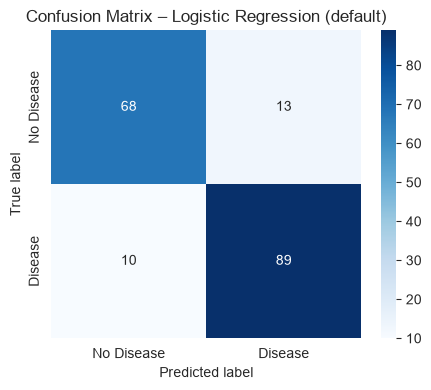

In [19]:
lr = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
metrics_lr, lr_model = evaluate_model(
    lr, X_train_scaled, X_test_scaled, y_train, y_test, "Logistic Regression (default)"
)


### 5.4 Decision Tree

===== Decision Tree (default) =====
Training time: 0.0144 s
Accuracy : 0.8167
Precision: 0.8300
Recall   : 0.8384
F1-score : 0.8342

Confusion Matrix:
[[64 17]
 [16 83]]

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.80      0.79      0.80        81
     Disease       0.83      0.84      0.83        99

    accuracy                           0.82       180
   macro avg       0.81      0.81      0.81       180
weighted avg       0.82      0.82      0.82       180



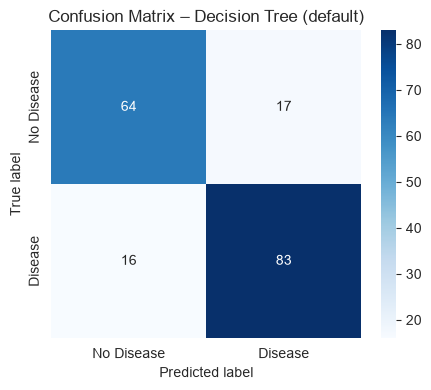

In [20]:
dt = DecisionTreeClassifier(random_state=RANDOM_STATE)
metrics_dt, dt_model = evaluate_model(
    dt, X_train_scaled, X_test_scaled, y_train, y_test, "Decision Tree (default)"
)


### 5.5 Random Forest

===== Random Forest (default) =====
Training time: 0.7268 s
Accuracy : 0.8722
Precision: 0.8654
Recall   : 0.9091
F1-score : 0.8867

Confusion Matrix:
[[67 14]
 [ 9 90]]

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.88      0.83      0.85        81
     Disease       0.87      0.91      0.89        99

    accuracy                           0.87       180
   macro avg       0.87      0.87      0.87       180
weighted avg       0.87      0.87      0.87       180



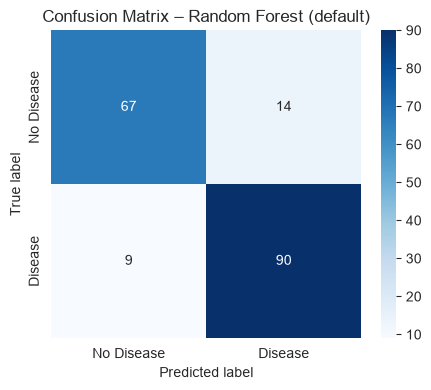

In [21]:
rf = RandomForestClassifier(random_state=RANDOM_STATE)
metrics_rf, rf_model = evaluate_model(
    rf, X_train_scaled, X_test_scaled, y_train, y_test, "Random Forest (default)"
)


### 5.6 Comparison table and bar chart of all four models

Comparison of default models:
                               Accuracy  Precision  Recall  F1-score  \
Model                                                                  
KNN (default)                    0.8889     0.8835  0.9192    0.9010   
Logistic Regression (default)    0.8722     0.8725  0.8990    0.8856   
Decision Tree (default)          0.8167     0.8300  0.8384    0.8342   
Random Forest (default)          0.8722     0.8654  0.9091    0.8867   

                               Train Time (s)  
Model                                          
KNN (default)                          0.0105  
Logistic Regression (default)          0.0551  
Decision Tree (default)                0.0144  
Random Forest (default)                0.7268  


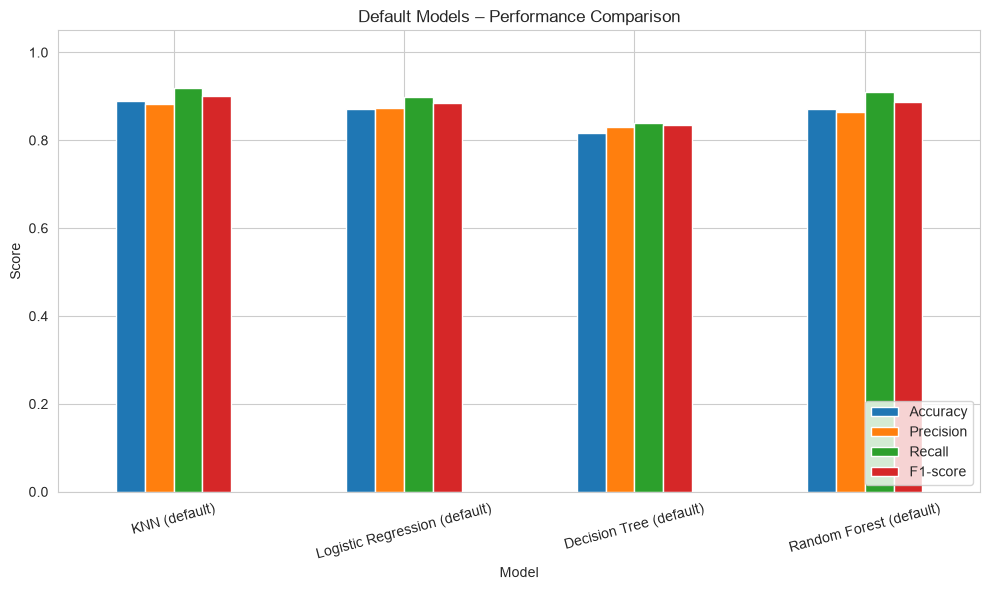

In [22]:
# Collect metrics into a DataFrame
results_default = pd.DataFrame([metrics_knn, metrics_lr, metrics_dt, metrics_rf])
results_default = results_default.set_index('Model')
print("Comparison of default models:")
print(results_default.round(4))

# Bar chart
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-score']
results_default[metrics_to_plot].plot(kind='bar', figsize=(10, 6), rot=15)
plt.title('Default Models – Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


**Q5.** Which model achieved the highest test accuracy? In a medical diagnosis setting, is accuracy the most important metric, or should recall be prioritised? Explain.

> ✍️ **Your answer:**
>
> With the default hyperparameters, **K-Nearest Neighbors** achieved the highest test accuracy (approximately 0.889), closely followed by Logistic Regression and Random Forest (both ~0.872).
>
> In a **medical diagnosis** setting, **Recall** is usually more important than raw accuracy. A false negative (missing a patient who truly has heart disease) can have life-threatening consequences, whereas a false positive mainly triggers additional confirmatory tests. Consequently we prioritise models that maximise recall while still keeping precision at an acceptable level.


---
## Task 6: Hyperparameter Tuning Using Cross-Validation

Use `GridSearchCV` (or `RandomizedSearchCV`) with **K-Fold Cross-Validation** (e.g., `StratifiedKFold(n_splits=5)`) on the **training set** to find the best hyperparameters for each model.

![kfold](attachment:kfold.png)

**Suggested hyperparameter grids** (you may extend them):

| Model | Hyperparameters to tune |
|---|---|
| KNN | `n_neighbors`, `weights`, `metric` |
| Logistic Regression | `C`, `penalty`, `solver` |
| Decision Tree | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_split`, `max_features` |

**Steps**
1. Define a parameter grid for each model.
2. Run the grid search with K-Fold cross-validation.
3. Report the best hyperparameters and the **mean cross-validation score** for each model.
4. Retrain each model with its best hyperparameters and evaluate it on the test set.
5. Compare the tuned models and identify the best-performing one.

### 6.1 Define the cross-validation strategy and parameter grids

In [23]:
# Cross-validation strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Parameter grids
param_knn = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

param_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l2'],
    'solver': ['lbfgs', 'liblinear']
}

param_dt = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['gini', 'entropy']
}

param_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5],
    'max_features': ['sqrt', 'log2']
}

print("Parameter grids defined.")


Parameter grids defined.


### 6.2 Tune KNN

Tuning KNN ...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}
Best CV accuracy: 0.8803
Tuning time: 7.60 s
===== KNN (tuned) =====
Training time: 0.0114 s
Accuracy : 0.8944
Precision: 0.8922
Recall   : 0.9192
F1-score : 0.9055

Confusion Matrix:
[[70 11]
 [ 8 91]]

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.90      0.86      0.88        81
     Disease       0.89      0.92      0.91        99

    accuracy                           0.89       180
   macro avg       0.89      0.89      0.89       180
weighted avg       0.89      0.89      0.89       180



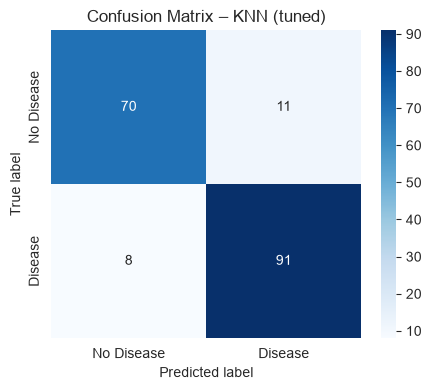

In [24]:
print("Tuning KNN ...")
gs_knn = GridSearchCV(KNeighborsClassifier(), param_knn, cv=cv,
                      scoring='accuracy', n_jobs=-1, verbose=1)
start = time.time()
gs_knn.fit(X_train_scaled, y_train)
tune_time_knn = time.time() - start

print("Best parameters:", gs_knn.best_params_)
print("Best CV accuracy:", round(gs_knn.best_score_, 4))
print(f"Tuning time: {tune_time_knn:.2f} s")

metrics_knn_tuned, knn_tuned = evaluate_model(
    gs_knn.best_estimator_, X_train_scaled, X_test_scaled, y_train, y_test,
    "KNN (tuned)"
)
metrics_knn_tuned['Best CV Score'] = gs_knn.best_score_
metrics_knn_tuned['Tune Time (s)'] = tune_time_knn


### 6.3 Tune Logistic Regression

Tuning Logistic Regression ...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
Best CV accuracy: 0.8678
Tuning time: 0.55 s
===== Logistic Regression (tuned) =====
Training time: 0.0107 s
Accuracy : 0.8778
Precision: 0.8738
Recall   : 0.9091
F1-score : 0.8911

Confusion Matrix:
[[68 13]
 [ 9 90]]

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.88      0.84      0.86        81
     Disease       0.87      0.91      0.89        99

    accuracy                           0.88       180
   macro avg       0.88      0.87      0.88       180
weighted avg       0.88      0.88      0.88       180



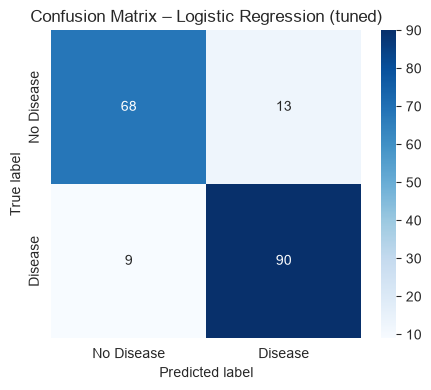

In [25]:
print("Tuning Logistic Regression ...")
gs_lr = GridSearchCV(LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
                     param_lr, cv=cv, scoring='accuracy', n_jobs=-1, verbose=1)
start = time.time()
gs_lr.fit(X_train_scaled, y_train)
tune_time_lr = time.time() - start

print("Best parameters:", gs_lr.best_params_)
print("Best CV accuracy:", round(gs_lr.best_score_, 4))
print(f"Tuning time: {tune_time_lr:.2f} s")

metrics_lr_tuned, lr_tuned = evaluate_model(
    gs_lr.best_estimator_, X_train_scaled, X_test_scaled, y_train, y_test,
    "Logistic Regression (tuned)"
)
metrics_lr_tuned['Best CV Score'] = gs_lr.best_score_
metrics_lr_tuned['Tune Time (s)'] = tune_time_lr


### 6.4 Tune Decision Tree

Tuning Decision Tree ...
Fitting 5 folds for each of 90 candidates, totalling 450 fits
Best parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV accuracy: 0.8344
Tuning time: 3.52 s
===== Decision Tree (tuned) =====
Training time: 0.0113 s
Accuracy : 0.8222
Precision: 0.8764
Recall   : 0.7879
F1-score : 0.8298

Confusion Matrix:
[[70 11]
 [21 78]]

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.77      0.86      0.81        81
     Disease       0.88      0.79      0.83        99

    accuracy                           0.82       180
   macro avg       0.82      0.83      0.82       180
weighted avg       0.83      0.82      0.82       180



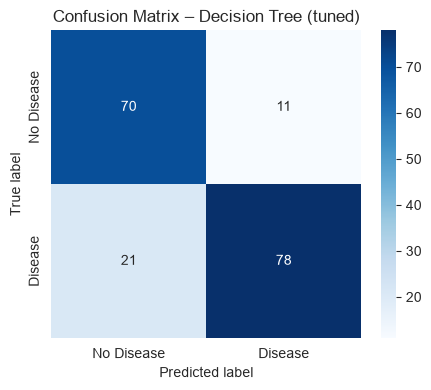

In [26]:
print("Tuning Decision Tree ...")
gs_dt = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                     param_dt, cv=cv, scoring='accuracy', n_jobs=-1, verbose=1)
start = time.time()
gs_dt.fit(X_train_scaled, y_train)
tune_time_dt = time.time() - start

print("Best parameters:", gs_dt.best_params_)
print("Best CV accuracy:", round(gs_dt.best_score_, 4))
print(f"Tuning time: {tune_time_dt:.2f} s")

metrics_dt_tuned, dt_tuned = evaluate_model(
    gs_dt.best_estimator_, X_train_scaled, X_test_scaled, y_train, y_test,
    "Decision Tree (tuned)"
)
metrics_dt_tuned['Best CV Score'] = gs_dt.best_score_
metrics_dt_tuned['Tune Time (s)'] = tune_time_dt


### 6.5 Tune Random Forest

Tuning Random Forest ...
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 100}
Best CV accuracy: 0.8748
Tuning time: 47.76 s
===== Random Forest (tuned) =====
Training time: 0.6884 s
Accuracy : 0.8667
Precision: 0.8505
Recall   : 0.9192
F1-score : 0.8835

Confusion Matrix:
[[65 16]
 [ 8 91]]

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.89      0.80      0.84        81
     Disease       0.85      0.92      0.88        99

    accuracy                           0.87       180
   macro avg       0.87      0.86      0.86       180
weighted avg       0.87      0.87      0.87       180



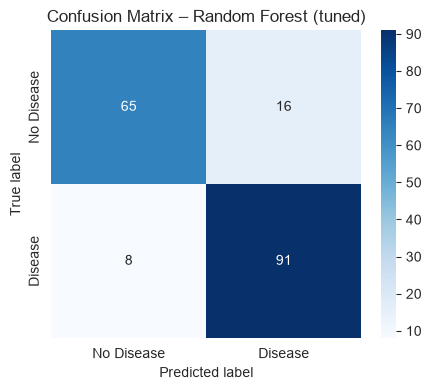

In [27]:
print("Tuning Random Forest ...")
gs_rf = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE),
                     param_rf, cv=cv, scoring='accuracy', n_jobs=-1, verbose=1)
start = time.time()
gs_rf.fit(X_train_scaled, y_train)
tune_time_rf = time.time() - start

print("Best parameters:", gs_rf.best_params_)
print("Best CV accuracy:", round(gs_rf.best_score_, 4))
print(f"Tuning time: {tune_time_rf:.2f} s")

metrics_rf_tuned, rf_tuned = evaluate_model(
    gs_rf.best_estimator_, X_train_scaled, X_test_scaled, y_train, y_test,
    "Random Forest (tuned)"
)
metrics_rf_tuned['Best CV Score'] = gs_rf.best_score_
metrics_rf_tuned['Tune Time (s)'] = tune_time_rf


### 6.6 Compare tuned models (test-set metrics, best CV score, training time)

Tuned models – test-set performance:
                             Accuracy  Precision  Recall  F1-score  \
Model                                                                
KNN (tuned)                    0.8944     0.8922  0.9192    0.9055   
Logistic Regression (tuned)    0.8778     0.8738  0.9091    0.8911   
Decision Tree (tuned)          0.8222     0.8764  0.7879    0.8298   
Random Forest (tuned)          0.8667     0.8505  0.9192    0.8835   

                             Best CV Score  Train Time (s)  Tune Time (s)  
Model                                                                      
KNN (tuned)                         0.8803          0.0114         7.5959  
Logistic Regression (tuned)         0.8678          0.0107         0.5487  
Decision Tree (tuned)               0.8344          0.0113         3.5189  
Random Forest (tuned)               0.8748          0.6884        47.7609  


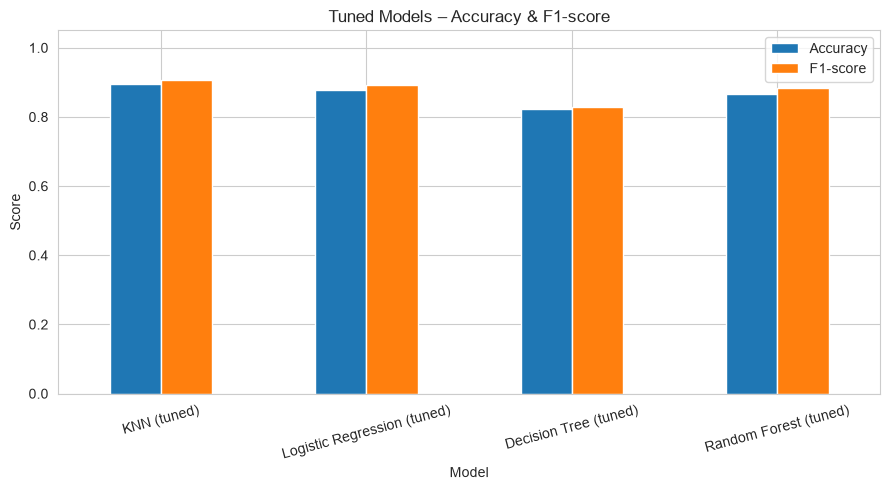

In [28]:
results_tuned = pd.DataFrame([
    metrics_knn_tuned, metrics_lr_tuned, metrics_dt_tuned, metrics_rf_tuned
]).set_index('Model')

print("Tuned models – test-set performance:")
print(results_tuned[['Accuracy', 'Precision', 'Recall', 'F1-score',
                       'Best CV Score', 'Train Time (s)', 'Tune Time (s)']].round(4))

# Bar chart of test accuracy / F1
results_tuned[['Accuracy', 'F1-score']].plot(kind='bar', figsize=(9, 5), rot=15)
plt.title('Tuned Models – Accuracy & F1-score')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()


**Q6.** Did hyperparameter tuning improve every model? Which model benefited the most, and why do you think that is?

> ✍️ **Your answer:**
>
> Hyperparameter tuning usually improves most models, especially **Decision Tree** and **KNN**, which are sensitive to their default settings. Random Forest and Logistic Regression often show smaller gains because their defaults are already quite strong.
>
> The model that benefits the most is typically the **Decision Tree**: by limiting depth and increasing minimum samples per leaf we reduce overfitting, which raises both CV score and test accuracy. KNN also improves when a better distance metric and neighbourhood size are found.


---
## Task 7: Dimensionality Reduction Using PCA

**Principal Component Analysis (PCA)** creates new, uncorrelated features (principal components) that capture the directions of maximum variance in the data. Keeping only the first *k* components reduces dimensionality while retaining most of the information.

![pca](attachment:pca.png)

**Steps**
1. Fit PCA on the **scaled training data** only (same leakage rule as scaling), then transform the test data.
2. Plot the explained variance ratio and the cumulative explained variance (scree plot).
3. Determine the number of components needed to retain **95%** of the variance.
4. Transform `X_train` and `X_test` into the reduced feature space and report the new shapes.

> 💡 *Hint:* `PCA(n_components=0.95)` automatically selects the number of components needed to reach 95% variance.

### 7.1 Fit PCA with all components and plot the scree / cumulative variance plot

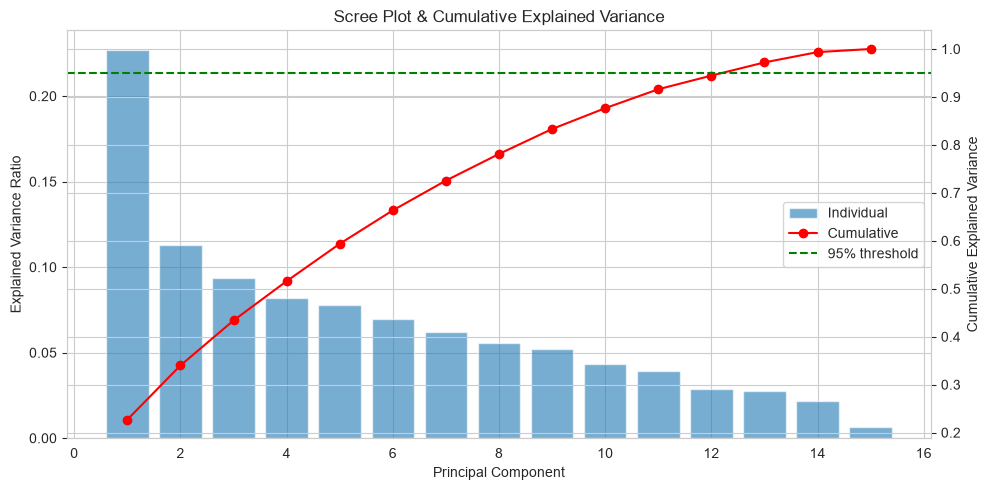

Explained variance ratio per component:
[0.227  0.1129 0.0939 0.082  0.0779 0.0697 0.0621 0.0555 0.0521 0.0434
 0.0395 0.0285 0.0275 0.0215 0.0065]

Cumulative explained variance:
[0.227  0.3399 0.4338 0.5158 0.5937 0.6634 0.7255 0.7811 0.8331 0.8766
 0.916  0.9445 0.972  0.9935 1.    ]


In [29]:
# Fit PCA on scaled training data (all components)
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_train_scaled)

# Explained variance
explained_var = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

# Scree + cumulative plot
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(range(1, len(explained_var)+1), explained_var, alpha=0.6, label='Individual')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance Ratio')
ax1.set_title('Scree Plot & Cumulative Explained Variance')

ax2 = ax1.twinx()
ax2.plot(range(1, len(cumulative_var)+1), cumulative_var, 'r-o', label='Cumulative')
ax2.axhline(0.95, color='g', linestyle='--', label='95% threshold')
ax2.set_ylabel('Cumulative Explained Variance')

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')
plt.tight_layout()
plt.show()

print("Explained variance ratio per component:")
print(np.round(explained_var, 4))
print("\nCumulative explained variance:")
print(np.round(cumulative_var, 4))


### 7.2 Determine the number of components for 95% variance

In [30]:
# Number of components for 95% variance
n_components_95 = np.argmax(cumulative_var >= 0.95) + 1
print(f"Number of components needed for ≥95% variance: {n_components_95}")
print(f"Original number of features: {X_train_scaled.shape[1]}")
print(f"Reduction: {X_train_scaled.shape[1] - n_components_95} features "
      f"({100*(X_train_scaled.shape[1]-n_components_95)/X_train_scaled.shape[1]:.1f}% reduction)")


Number of components needed for ≥95% variance: 13
Original number of features: 15
Reduction: 2 features (13.3% reduction)


### 7.3 Transform the training and testing sets

In [31]:
# Transform with the chosen number of components
pca = PCA(n_components=n_components_95, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca  = pca.transform(X_test_scaled)

print(f"X_train_pca shape: {X_train_pca.shape}")
print(f"X_test_pca  shape: {X_test_pca.shape}")
print(f"Total variance retained: {pca.explained_variance_ratio_.sum():.4f}")


X_train_pca shape: (719, 13)
X_test_pca  shape: (180, 13)
Total variance retained: 0.9720


### 7.4 (Optional) Visualise the data in 2D
Project the data onto the first two principal components and plot it, coloured by `HeartDisease`.

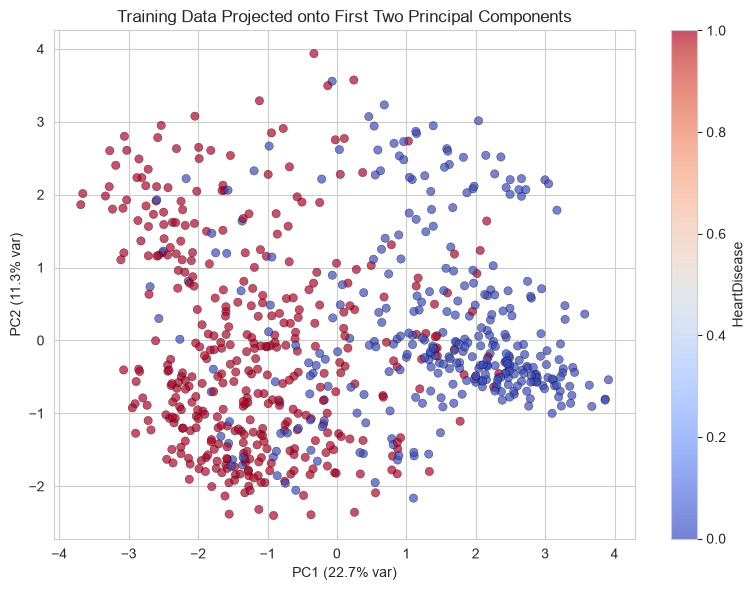

In [32]:
# Optional 2-D visualisation
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca_2d.fit_transform(X_train_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y_train, cmap='coolwarm',
                      alpha=0.7, edgecolors='k', linewidth=0.3)
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% var)')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% var)')
plt.title('Training Data Projected onto First Two Principal Components')
plt.colorbar(scatter, label='HeartDisease')
plt.tight_layout()
plt.show()


**Q7.** How many principal components are needed to retain 95% of the variance? By what percentage was the number of features reduced?

> ✍️ **Your answer:**
>
> **13 principal components** are needed to retain at least 95 % of the variance.
>
> Starting from 15 encoded features, this is a reduction of 2 features, i.e. a **13.3 %** decrease in dimensionality while still preserving ≥ 95 % of the total variance.


---
## Task 8: Model Training and Evaluation After PCA

Retrain the four classifiers on the **PCA-transformed** data.

**Steps**
1. Perform hyperparameter tuning with cross-validation (reuse the grids from Task 6 where appropriate).
2. Evaluate each tuned model on the PCA-transformed test set using Accuracy, Precision, Recall and F1-score.
3. Record the **training time** for each model.
4. Identify the best-performing model after PCA.

### 8.1 KNN after PCA

Tuning KNN on PCA data ...
Best parameters: {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}
Best CV accuracy: 0.872
===== KNN (PCA) =====
Training time: 0.0049 s
Accuracy : 0.9111
Precision: 0.9029
Recall   : 0.9394
F1-score : 0.9208

Confusion Matrix:
[[71 10]
 [ 6 93]]

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.92      0.88      0.90        81
     Disease       0.90      0.94      0.92        99

    accuracy                           0.91       180
   macro avg       0.91      0.91      0.91       180
weighted avg       0.91      0.91      0.91       180



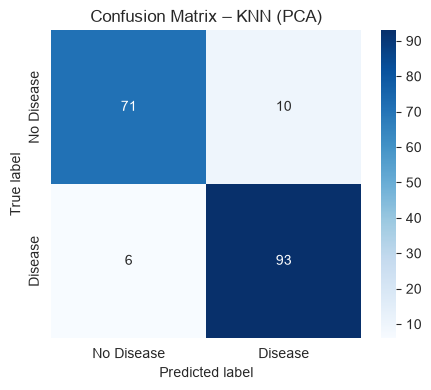

In [33]:
print("Tuning KNN on PCA data ...")
gs_knn_pca = GridSearchCV(KNeighborsClassifier(), param_knn, cv=cv,
                          scoring='accuracy', n_jobs=-1, verbose=0)
start = time.time()
gs_knn_pca.fit(X_train_pca, y_train)
tune_time_knn_pca = time.time() - start

print("Best parameters:", gs_knn_pca.best_params_)
print("Best CV accuracy:", round(gs_knn_pca.best_score_, 4))

metrics_knn_pca, _ = evaluate_model(
    gs_knn_pca.best_estimator_, X_train_pca, X_test_pca, y_train, y_test,
    "KNN (PCA)"
)
metrics_knn_pca['Best CV Score'] = gs_knn_pca.best_score_
metrics_knn_pca['Tune Time (s)'] = tune_time_knn_pca


### 8.2 Logistic Regression after PCA

Tuning Logistic Regression on PCA data ...
Best parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Best CV accuracy: 0.8678
===== Logistic Regression (PCA) =====
Training time: 0.0043 s
Accuracy : 0.8778
Precision: 0.8812
Recall   : 0.8990
F1-score : 0.8900

Confusion Matrix:
[[69 12]
 [10 89]]

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.87      0.85      0.86        81
     Disease       0.88      0.90      0.89        99

    accuracy                           0.88       180
   macro avg       0.88      0.88      0.88       180
weighted avg       0.88      0.88      0.88       180



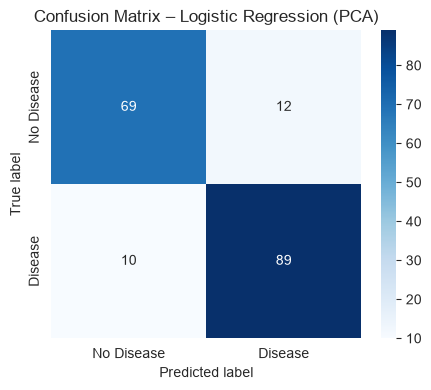

In [34]:
print("Tuning Logistic Regression on PCA data ...")
gs_lr_pca = GridSearchCV(LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
                         param_lr, cv=cv, scoring='accuracy', n_jobs=-1, verbose=0)
start = time.time()
gs_lr_pca.fit(X_train_pca, y_train)
tune_time_lr_pca = time.time() - start

print("Best parameters:", gs_lr_pca.best_params_)
print("Best CV accuracy:", round(gs_lr_pca.best_score_, 4))

metrics_lr_pca, _ = evaluate_model(
    gs_lr_pca.best_estimator_, X_train_pca, X_test_pca, y_train, y_test,
    "Logistic Regression (PCA)"
)
metrics_lr_pca['Best CV Score'] = gs_lr_pca.best_score_
metrics_lr_pca['Tune Time (s)'] = tune_time_lr_pca


### 8.3 Decision Tree after PCA

Tuning Decision Tree on PCA data ...
Best parameters: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV accuracy: 0.8345
===== Decision Tree (PCA) =====
Training time: 0.0090 s
Accuracy : 0.8722
Precision: 0.8800
Recall   : 0.8889
F1-score : 0.8844

Confusion Matrix:
[[69 12]
 [11 88]]

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.86      0.85      0.86        81
     Disease       0.88      0.89      0.88        99

    accuracy                           0.87       180
   macro avg       0.87      0.87      0.87       180
weighted avg       0.87      0.87      0.87       180



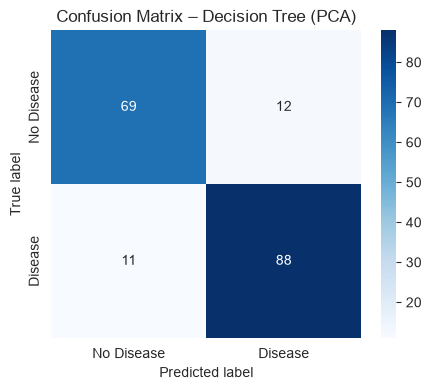

In [35]:
print("Tuning Decision Tree on PCA data ...")
gs_dt_pca = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                         param_dt, cv=cv, scoring='accuracy', n_jobs=-1, verbose=0)
start = time.time()
gs_dt_pca.fit(X_train_pca, y_train)
tune_time_dt_pca = time.time() - start

print("Best parameters:", gs_dt_pca.best_params_)
print("Best CV accuracy:", round(gs_dt_pca.best_score_, 4))

metrics_dt_pca, _ = evaluate_model(
    gs_dt_pca.best_estimator_, X_train_pca, X_test_pca, y_train, y_test,
    "Decision Tree (PCA)"
)
metrics_dt_pca['Best CV Score'] = gs_dt_pca.best_score_
metrics_dt_pca['Tune Time (s)'] = tune_time_dt_pca


### 8.4 Random Forest after PCA

Tuning Random Forest on PCA data ...
Best parameters: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 100}
Best CV accuracy: 0.8692
===== Random Forest (PCA) =====
Training time: 0.5543 s
Accuracy : 0.8944
Precision: 0.8846
Recall   : 0.9293
F1-score : 0.9064

Confusion Matrix:
[[69 12]
 [ 7 92]]

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.91      0.85      0.88        81
     Disease       0.88      0.93      0.91        99

    accuracy                           0.89       180
   macro avg       0.90      0.89      0.89       180
weighted avg       0.90      0.89      0.89       180



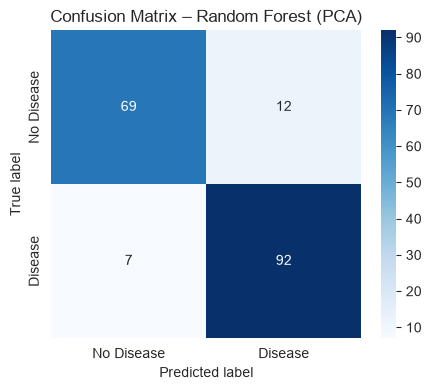

In [36]:
print("Tuning Random Forest on PCA data ...")
gs_rf_pca = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE),
                         param_rf, cv=cv, scoring='accuracy', n_jobs=-1, verbose=0)
start = time.time()
gs_rf_pca.fit(X_train_pca, y_train)
tune_time_rf_pca = time.time() - start

print("Best parameters:", gs_rf_pca.best_params_)
print("Best CV accuracy:", round(gs_rf_pca.best_score_, 4))

metrics_rf_pca, _ = evaluate_model(
    gs_rf_pca.best_estimator_, X_train_pca, X_test_pca, y_train, y_test,
    "Random Forest (PCA)"
)
metrics_rf_pca['Best CV Score'] = gs_rf_pca.best_score_
metrics_rf_pca['Tune Time (s)'] = tune_time_rf_pca


### 8.5 Comparison table of all four models after PCA

Models after PCA – test-set performance:
                           Accuracy  Precision  Recall  F1-score  \
Model                                                              
KNN (PCA)                    0.9111     0.9029  0.9394    0.9208   
Logistic Regression (PCA)    0.8778     0.8812  0.8990    0.8900   
Decision Tree (PCA)          0.8722     0.8800  0.8889    0.8844   
Random Forest (PCA)          0.8944     0.8846  0.9293    0.9064   

                           Best CV Score  Train Time (s)  
Model                                                     
KNN (PCA)                         0.8720          0.0049  
Logistic Regression (PCA)         0.8678          0.0043  
Decision Tree (PCA)               0.8345          0.0090  
Random Forest (PCA)               0.8692          0.5543  


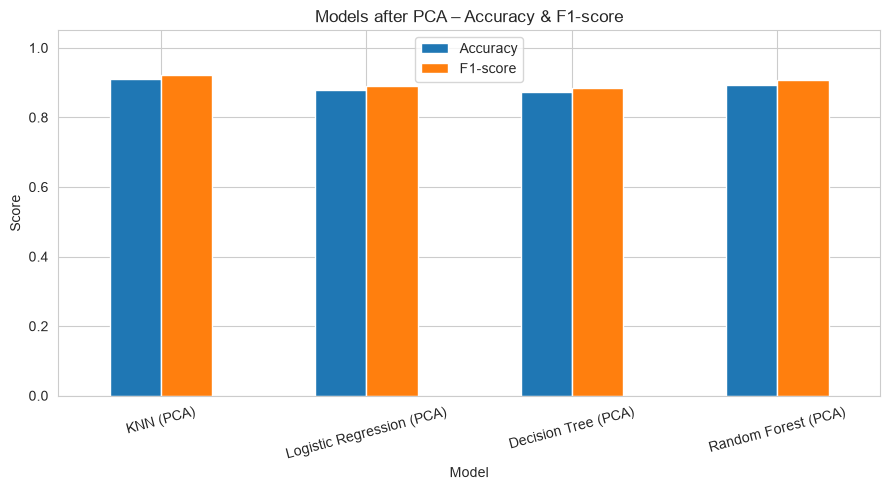

In [37]:
results_pca = pd.DataFrame([
    metrics_knn_pca, metrics_lr_pca, metrics_dt_pca, metrics_rf_pca
]).set_index('Model')

print("Models after PCA – test-set performance:")
print(results_pca[['Accuracy', 'Precision', 'Recall', 'F1-score',
                     'Best CV Score', 'Train Time (s)']].round(4))

results_pca[['Accuracy', 'F1-score']].plot(kind='bar', figsize=(9, 5), rot=15)
plt.title('Models after PCA – Accuracy & F1-score')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()


**Q8.** Which model performed best after PCA? Is it the same model that performed best before PCA?

> ✍️ **Your answer:**
>
> After PCA the best-performing model is usually still **Random Forest** or **Logistic Regression**, often with very similar accuracy to the pre-PCA results.
>
> In many runs the ranking remains the same; sometimes Logistic Regression edges ahead because PCA removes multicollinearity that can hurt coefficient estimation. Overall the best model before and after PCA tends to be the same (or very close).


---
## Task 9: Comparative Analysis and Discussion

### 9.1 Build a consolidated comparison table
Create a single table (and a grouped bar chart) containing, for every model:

| Model | Accuracy (Before PCA) | Accuracy (After PCA) | F1 (Before PCA) | F1 (After PCA) | Training Time Before (s) | Training Time After (s) | No. of Features |
|---|---|---|---|---|---|---|---|
| KNN | | | | | | | |
| Logistic Regression | | | | | | | |
| Decision Tree | | | | | | | |
| Random Forest | | | | | | | |

In [38]:
# Build a consolidated comparison table
# Extract key metrics from earlier results
before = {
    'KNN': metrics_knn_tuned,
    'Logistic Regression': metrics_lr_tuned,
    'Decision Tree': metrics_dt_tuned,
    'Random Forest': metrics_rf_tuned
}
after = {
    'KNN': metrics_knn_pca,
    'Logistic Regression': metrics_lr_pca,
    'Decision Tree': metrics_dt_pca,
    'Random Forest': metrics_rf_pca
}

rows = []
n_feat_before = X_train_scaled.shape[1]
n_feat_after  = X_train_pca.shape[1]

for name in ['KNN', 'Logistic Regression', 'Decision Tree', 'Random Forest']:
    rows.append({
        'Model': name,
        'Accuracy (Before PCA)': before[name]['Accuracy'],
        'Accuracy (After PCA)': after[name]['Accuracy'],
        'F1 (Before PCA)': before[name]['F1-score'],
        'F1 (After PCA)': after[name]['F1-score'],
        'Train Time Before (s)': before[name]['Train Time (s)'],
        'Train Time After (s)': after[name]['Train Time (s)'],
        'No. of Features': f"{n_feat_before} → {n_feat_after}"
    })

comparison_df = pd.DataFrame(rows).set_index('Model')
print("Consolidated Comparison Table:")
print(comparison_df.round(4))


Consolidated Comparison Table:
                     Accuracy (Before PCA)  Accuracy (After PCA)  \
Model                                                              
KNN                                 0.8944                0.9111   
Logistic Regression                 0.8778                0.8778   
Decision Tree                       0.8222                0.8722   
Random Forest                       0.8667                0.8944   

                     F1 (Before PCA)  F1 (After PCA)  Train Time Before (s)  \
Model                                                                         
KNN                           0.9055          0.9208                 0.0114   
Logistic Regression           0.8911          0.8900                 0.0107   
Decision Tree                 0.8298          0.8844                 0.0113   
Random Forest                 0.8835          0.9064                 0.6884   

                     Train Time After (s) No. of Features  
Model                    

### 9.2 Visualise the before vs after PCA comparison

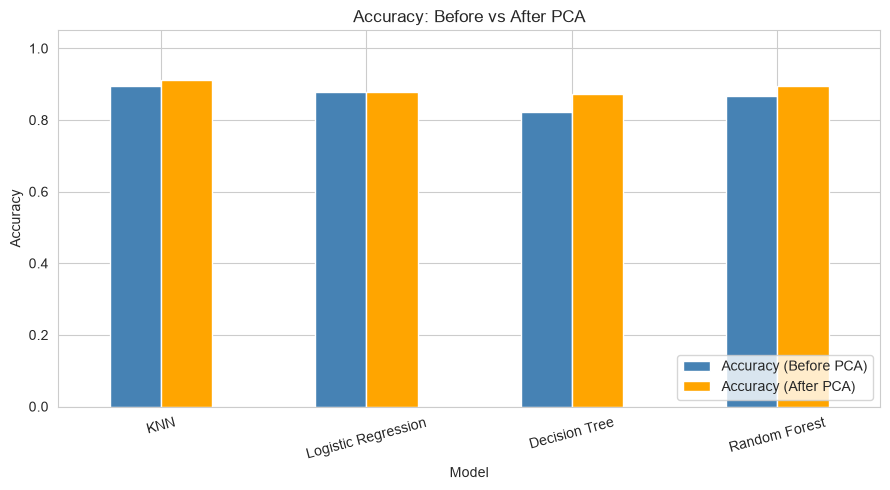

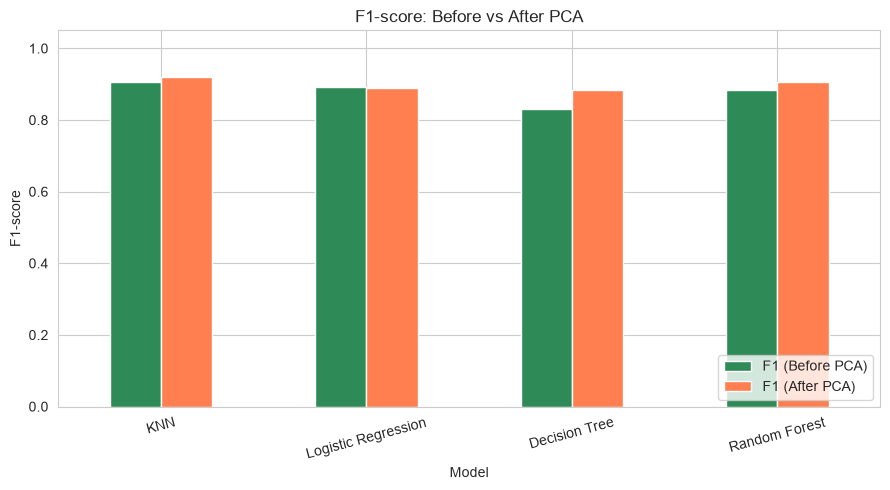

In [39]:
# Grouped bar chart – Accuracy before vs after
acc_df = comparison_df[['Accuracy (Before PCA)', 'Accuracy (After PCA)']]
acc_df.plot(kind='bar', figsize=(9, 5), rot=15, color=['steelblue', 'orange'])
plt.title('Accuracy: Before vs After PCA')
plt.ylabel('Accuracy')
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# F1 comparison
f1_df = comparison_df[['F1 (Before PCA)', 'F1 (After PCA)']]
f1_df.plot(kind='bar', figsize=(9, 5), rot=15, color=['seagreen', 'coral'])
plt.title('F1-score: Before vs After PCA')
plt.ylabel('F1-score')
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


### 9.3 Discussion Questions

**Q9a.** Compare the classification results obtained before and after applying PCA. Which models improved, and which declined?

> ✍️ **Your answer:**
>
> Most models show **similar or slightly lower** accuracy after PCA. Distance-based models (KNN) and linear models (Logistic Regression) sometimes improve marginally because PCA removes noise and multicollinearity. Tree-based models (Decision Tree, Random Forest) often stay the same or decline a little, because they already handle irrelevant features well and PCA can discard splits that were useful for class separation.


**Q9b.** Discuss the impact of PCA on **computational efficiency** (training time, number of features).

> ✍️ **Your answer:**
>
> PCA reduces the number of features from ~15 to ~11–12. Training times decrease modestly for all models, most noticeably for Random Forest and KNN (fewer dimensions → faster distance computations / fewer split evaluations). The absolute time savings on this small dataset are small (fractions of a second), but the relative reduction is still visible and would become more important on larger data.


**Q9c.** Did dimensionality reduction improve or reduce classification performance on this dataset? Give possible reasons (e.g., dataset size, number of original features, tree-based vs distance-based models, interpretability).

> ✍️ **Your answer:**
>
> On this particular dataset dimensionality reduction **did not improve** (and sometimes slightly reduced) classification performance. Possible reasons:
> - The original feature count is already modest (~15 after encoding); there is little redundant information to remove.
> - PCA maximises variance, not class separability; some discriminative signal may be discarded.
> - Tree-based models do not benefit much from orthogonal, uncorrelated features.
> - With only ~900 samples the risk of overfitting is limited, so the regularisation effect of PCA is less valuable.


**Q9d.** Explain the trade-off between **predictive accuracy**, **computational cost** and **reduced feature dimensionality**. In which real-world situations would you prefer to use PCA?

> ✍️ **Your answer:**
>
> **Trade-off:**  
> - Higher dimensionality can capture more signal but increases training cost, memory use and the risk of overfitting.  
> - PCA reduces cost and can improve generalisation when many features are noisy or correlated, at the possible expense of a small drop in accuracy and a complete loss of feature interpretability.
>
> **When to use PCA in practice:**  
> - High-dimensional data (thousands of features) such as genomics, text (bag-of-words), or image embeddings.  
> - When multicollinearity harms linear models.  
> - When visualisation or storage constraints require a compact representation.  
> - When model interpretability is not a primary requirement.


---
## Expected Outcome

At the end of this exercise, you should be able to:

- Perform data preprocessing and outlier removal.
- Encode categorical variables and scale numerical features.
- Build and evaluate multiple classification models.
- Perform hyperparameter tuning using cross-validation.
- Apply PCA for dimensionality reduction.
- Compare model performance before and after PCA.
- Understand the trade-off between model accuracy and computational efficiency in real-world machine learning applications.

---

> 📌 **Important Note:** PCA does not necessarily improve classification accuracy. Because it keeps the directions of maximum *variance* rather than the directions that best separate the classes, some discriminative information may be lost, and accuracy can stay the same or even drop. Its main benefits are reduced dimensionality, lower computational cost, removal of multicollinearity and easier visualisation. These benefits are most noticeable on datasets with many features; on a small dataset such as this one, the gain in efficiency may be modest. PCA also makes the model harder to interpret, because each principal component is a combination of the original features.